# Adding Problem: Long-Term Dependency Learning Task

This notebook implements the adding problem, a benchmark task for evaluating the ability of RNNs to learn long-term dependencies. The task requires computing the sum of two specific numbers from a sequence of random numbers.

## Task Description

- Input: 2-dimensional vector at each time step
  - First dimension: Random number in [0, 1]
  - Second dimension: Boolean indicator (1 for numbers to add, 0 otherwise)
- Sequence length: 20 time steps
- Objective: Sum the two numbers where the boolean indicator is 1
- This tests the network's ability to remember and combine information from different time steps

We will compare the performance of two network architectures:

1. **Net**: RNN with excitatory/inhibitory separation
2. **SimpleNet**: Standard vanilla RNN


## 1. Setup and Imports


In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import warnings
warnings.filterwarnings('ignore')

from pdm_model import Net, SimpleNet

# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: cuda


## 2. Adding Problem Dataset


In [2]:
class AddingProblemDataset(Dataset):
    """
    Dataset for the adding problem task.

    Args:
        seq_len: Length of the sequence (default: 20)
        num_samples: Number of samples in the dataset
    """

    def __init__(self, seq_len=20, num_samples=1000):

        np.random.seed(42)  # For reproducibility

        self.seq_len = seq_len
        self.num_samples = num_samples

        # # Generate all data at once for consistency
        # self.data = []
        # self.targets = []

        # for _ in range(num_samples):
        #     # Generate random sequence of numbers [0, 1]
        #     numbers = np.random.uniform(0, 1, seq_len)

        #     # Generate indicator sequence (exactly 2 positions are marked)
        #     indicators = np.zeros(seq_len)
        #     # Randomly select 2 positions to mark
        #     marked_positions = np.random.choice(seq_len, size=2, replace=False)
        #     indicators[marked_positions] = 1

        #     # Combine into input sequence (seq_len, 2)
        #     input_seq = np.stack([numbers, indicators], axis=1)

        #     # Target is the sum of the two marked numbers
        #     target = numbers[marked_positions].sum()

        #     self.data.append(input_seq)
        #     self.targets.append(target)
        numbers = np.random.uniform(0, 1, (num_samples, seq_len))
        indicators = np.random.choice(2, size=(num_samples, seq_len), p=[0.8, 0.2])
        self.data = torch.FloatTensor(np.stack([numbers, indicators], axis=2))
        self.targets = torch.FloatTensor((numbers * indicators).sum(axis=1))


    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        return self.data[idx], self.targets[idx]

# Create datasets
train_dataset = AddingProblemDataset(seq_len=20, num_samples=50000)
test_dataset = AddingProblemDataset(seq_len=20, num_samples=1000)

print(f"Training dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

# Show example
sample_input, sample_target = train_dataset[0]
print(f"\nExample input shape: {sample_input.shape}")
print(f"Example target: {sample_target:.4f}")
print(f"\nFirst few time steps:")
for i in range(20):
    print(f"t={i}: number={sample_input[i, 0]:.4f}, indicator={sample_input[i, 1]:.0f}")

Training dataset size: 50000
Test dataset size: 1000

Example input shape: torch.Size([20, 2])
Example target: 2.4754

First few time steps:
t=0: number=0.3745, indicator=0
t=1: number=0.9507, indicator=0
t=2: number=0.7320, indicator=0
t=3: number=0.5987, indicator=0
t=4: number=0.1560, indicator=1
t=5: number=0.1560, indicator=0
t=6: number=0.0581, indicator=0
t=7: number=0.8662, indicator=0
t=8: number=0.6011, indicator=0
t=9: number=0.7081, indicator=1
t=10: number=0.0206, indicator=0
t=11: number=0.9699, indicator=0
t=12: number=0.8324, indicator=1
t=13: number=0.2123, indicator=0
t=14: number=0.1818, indicator=0
t=15: number=0.1834, indicator=1
t=16: number=0.3042, indicator=1
t=17: number=0.5248, indicator=0
t=18: number=0.4319, indicator=0
t=19: number=0.2912, indicator=1


## 3. Visualize Sample Data


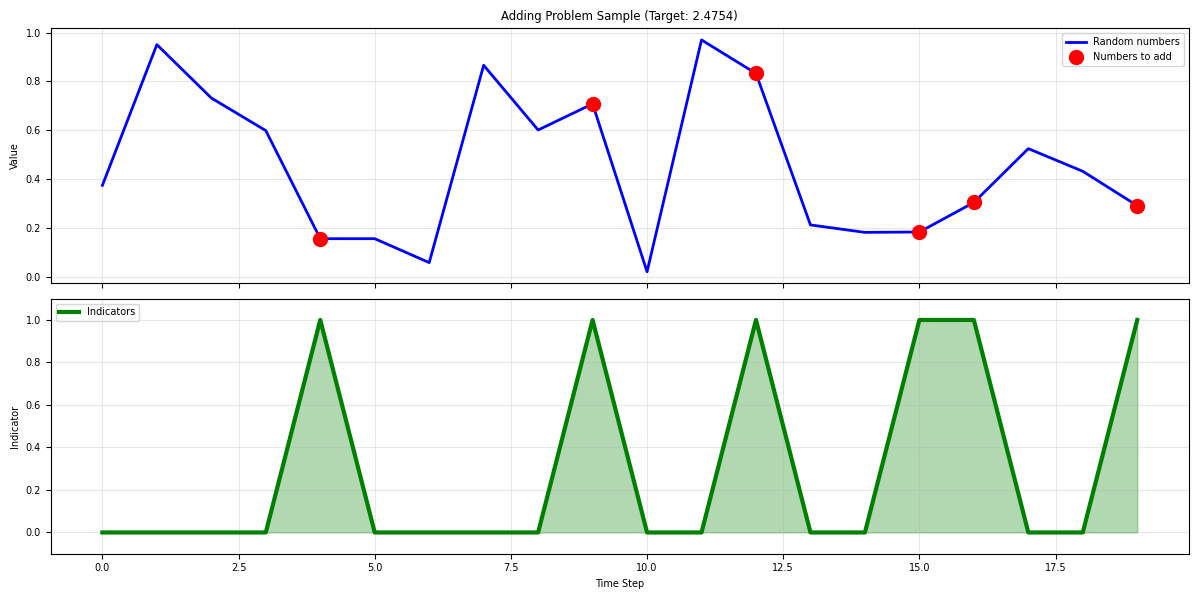

Marked positions: [ 4  9 12 15 16 19]
Values to add: [0.15601864 0.7080726  0.83244264 0.1834045  0.30424225 0.29122913]
Sum: 2.4754
Target: 2.4754


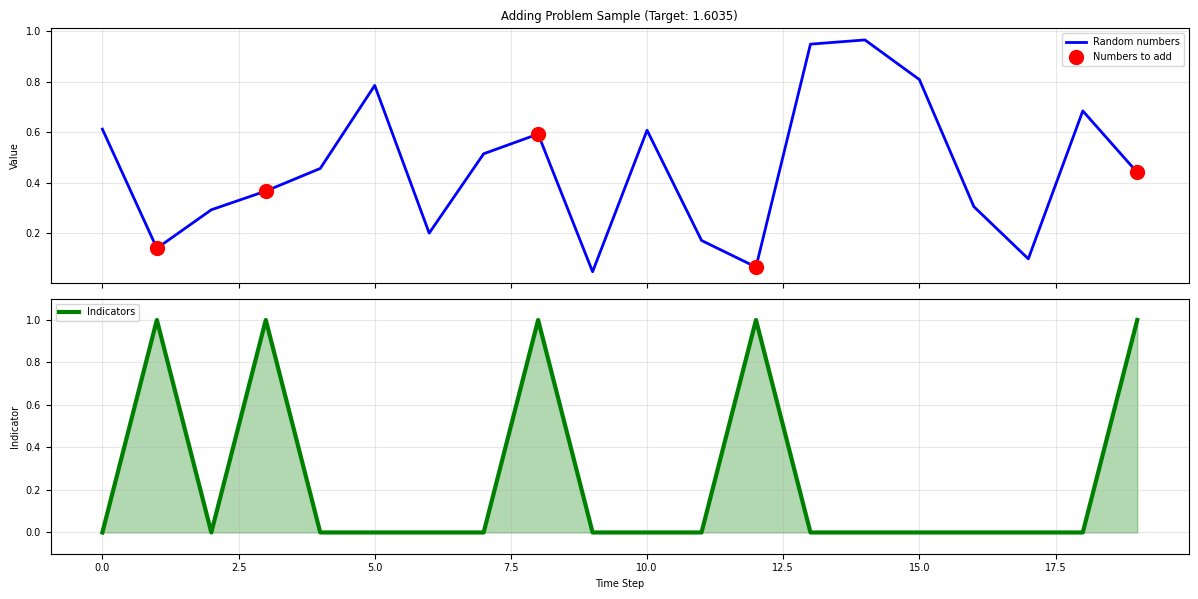

Marked positions: [ 1  3  8 12 19]
Values to add: [0.13949387 0.36636186 0.59241456 0.06505159 0.4401525 ]
Sum: 1.6035
Target: 1.6035


In [3]:
def visualize_adding_problem_sample(dataset, idx=0):
    """
    Visualize a sample from the adding problem dataset.
    """
    input_seq, target = dataset[idx]
    seq_len = input_seq.shape[0]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

    # Plot the random numbers
    ax1.plot(range(seq_len), input_seq[:, 0], 'b-', linewidth=2, label='Random numbers')
    # Highlight the numbers to be added
    marked_indices = np.where(input_seq[:, 1] == 1)[0]
    ax1.scatter(marked_indices, input_seq[marked_indices, 0],
               color='red', s=100, zorder=5, label='Numbers to add')
    ax1.set_ylabel('Value')
    ax1.set_title(f'Adding Problem Sample (Target: {target:.4f})')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Plot the indicators
    ax2.plot(range(seq_len), input_seq[:, 1], 'g-', linewidth=3, label='Indicators')
    ax2.fill_between(range(seq_len), input_seq[:, 1], alpha=0.3, color='green')
    ax2.set_xlabel('Time Step')
    ax2.set_ylabel('Indicator')
    ax2.set_ylim(-0.1, 1.1)
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Print details
    print(f"Marked positions: {marked_indices}")
    print(f"Values to add: {input_seq[marked_indices, 0].numpy()}")
    print(f"Sum: {input_seq[marked_indices, 0].sum():.4f}")
    print(f"Target: {target:.4f}")

# Visualize a few samples
visualize_adding_problem_sample(train_dataset, 0)
visualize_adding_problem_sample(train_dataset, 1)

## 4. Training Functions


In [ ]:
def train_model(model, train_dataset, test_dataset, epochs=100, lr=0.001, batch_size=64):
    """
    Train a model on the adding problem.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    # criterion = nn.L1Loss()

    train_losses = torch.zeros(epochs)
    test_every = 100
    test_losses = torch.zeros(epochs // test_every)

    model.train()
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    loader = iter(train_loader)
    for epoch in range(epochs):
        # print(epoch)
        # Training
        total_train_loss = 0
        num_batches = 0

        # for batch_inputs, batch_targets in train_loader:
        try:
            batch_inputs, batch_targets = next(loader)
        except StopIteration:
            train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
            loader = iter(train_loader)
            batch_inputs, batch_targets = next(loader)
        batch_inputs = batch_inputs.to(device).transpose(0, 1)  # (seq_len, batch_size, input_size)
        # print('batch_targets:', batch_targets.shape)
        batch_targets = batch_targets.to(device)

        optimizer.zero_grad()

        # Forward pass
        outputs, eimask_logit, hidden = model(batch_inputs)

        # Use the last output for regression
        predictions = outputs[-1, :, 0]  # Last time step, all batches, first output

        decoding_loss = criterion(predictions, batch_targets)

        if model.entropy_loss:
            eimask_prob = F.softmax(eimask_logit, dim=-1)
            eimask_entropy = -torch.sum(eimask_prob * torch.log(eimask_prob + 1e-10), dim=-1)
            entropy_loss = torch.mean(eimask_entropy)  # Add entropy regularization
        else:
            entropy_loss = 0.0

        loss = 1 * entropy_loss + decoding_loss
        # Backward pass
        loss.backward()
        # Gradient clipping for stability
        # torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()

        total_train_loss += loss.item()
        num_batches += 1

        avg_train_loss = total_train_loss / num_batches
        train_losses[epoch] = avg_train_loss

        # Testing
        if epoch % test_every == 0:
            model.eval()
            total_test_loss = 0
            num_test_batches = 0

            with torch.no_grad():
                for batch_inputs, batch_targets in test_loader:
                    batch_inputs = batch_inputs.to(device).transpose(0, 1)
                    batch_targets = batch_targets.to(device)

                    outputs, _, hidden = model(batch_inputs)
                    predictions = outputs[-1, :, 0]

                    loss = criterion(predictions, batch_targets)
                    total_test_loss += loss.item()
                    num_test_batches += 1

            avg_test_loss = total_test_loss / num_test_batches
            test_losses[epoch // test_every] = avg_test_loss

            print(f'Epoch [{epoch:4d}/{epochs}], Train Loss: {avg_train_loss:.6f}, Test Loss: {avg_test_loss:.6f}')

            model.train()

    return train_losses, test_losses

def evaluate_model(model, test_loader):
    """
    Evaluate model performance on test set.
    """
    model.eval()
    total_loss = 0
    predictions = []
    targets = []

    criterion = nn.MSELoss()

    with torch.no_grad():
        for batch_inputs, batch_targets in test_loader:
            batch_inputs = batch_inputs.to(device).transpose(0, 1)
            batch_targets = batch_targets.to(device)

            outputs, _, hidden = model(batch_inputs)
            preds = outputs[-1, :, 0]

            loss = criterion(preds, batch_targets)
            total_loss += loss.item()

            predictions.extend(preds.cpu().numpy())
            targets.extend(batch_targets.cpu().numpy())

    avg_loss = total_loss / len(test_loader)
    mse = np.mean((np.array(predictions) - np.array(targets)) ** 2)
    mae = np.mean(np.abs(np.array(predictions) - np.array(targets)))

    return avg_loss, mse, mae, predictions, targets

## 5. Experiment: Compare Net vs SimpleNet


In [ ]:
# Experiment parameters
n_seeds = 5
epochs = 3000
batch_size = 64
hidden_size = 64
input_size = 2  # [number, indicator]
output_size = 1  # regression output

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Storage for results
results = {
    'net': {'train_losses': [], 'test_losses': [], 'final_mse': [], 'final_mae': [], 'correlation':[]},
    'simple': {'train_losses': [], 'test_losses': [], 'final_mse': [], 'final_mae': [], 'correlation':[]}
}

print(f"Running experiment with {n_seeds} seeds...\n")
lr_ei = 1e-2
lr_simple = 1e-2
for seed in range(n_seeds):
    print(f"=== Seed {seed + 1}/{n_seeds} ===")

    # Set random seeds for reproducibility
    torch.manual_seed(seed)
    np.random.seed(seed)

    # Train SimpleNet (vanilla RNN)
    print("Training SimpleNet (vanilla RNN)...")
    simple_net = SimpleNet(ob_size=input_size, num_h=hidden_size, act_size=output_size).to(device)
    train_losses_simple, test_losses_simple = train_model(simple_net, train_dataset, test_dataset,
                                                          epochs=epochs,lr=lr_simple, batch_size=batch_size)

    # Evaluate SimpleNet
    _, mse_simple, mae_simple, simple_predictions, simple_targets = evaluate_model(simple_net, test_loader)

    results['simple']['train_losses'].append(train_losses_simple.detach().cpu().numpy())
    results['simple']['test_losses'].append(test_losses_simple.detach().cpu().numpy())
    results['simple']['final_mse'].append(mse_simple)
    results['simple']['final_mae'].append(mae_simple)
    results['simple']['correlation'].append(np.corrcoef(simple_predictions, simple_targets)[0, 1])

    print(f"SimpleNet - Final MSE: {mse_simple:.6f}, MAE: {mae_simple:.6f}")

    # Train Net (EI-separated RNN)
    print("Training Net (EI-separated RNN)...")
    net = Net(ob_size=input_size, num_h=hidden_size, act_size=output_size, entropy_loss=True).to(device)
    train_losses_net, test_losses_net = train_model(net, train_dataset, test_dataset,
                                                    epochs=epochs, lr=lr_ei, batch_size=batch_size)

    # Evaluate Net
    _, mse_net, mae_net, net_predictions, net_targets = evaluate_model(net, test_loader)

    results['net']['train_losses'].append(train_losses_net)
    results['net']['test_losses'].append(test_losses_net)
    results['net']['final_mse'].append(mse_net)
    results['net']['final_mae'].append(mae_net)
    results['net']['correlation'].append(np.corrcoef(net_predictions, net_targets)[0, 1])

    print(f"Net - Final MSE: {mse_net:.6f}, MAE: {mae_net:.6f}")


    print()

print("Experiment completed!")

Running experiment with 5 seeds...

=== Seed 1/5 ===
Training SimpleNet (vanilla RNN)...
Epoch [   0/3000], Train Loss: 5.667422, Test Loss: 1.658205
Epoch [ 100/3000], Train Loss: 1.288756, Test Loss: 1.114632
Epoch [ 200/3000], Train Loss: 1.257152, Test Loss: 1.333639
Epoch [ 300/3000], Train Loss: 1.281418, Test Loss: 1.055894
Epoch [ 400/3000], Train Loss: 0.746997, Test Loss: 0.988878
Epoch [ 500/3000], Train Loss: 0.903965, Test Loss: 1.037399
Epoch [ 600/3000], Train Loss: 0.701305, Test Loss: 0.807009
Epoch [ 700/3000], Train Loss: 1.705706, Test Loss: 1.406318


StopIteration: 

## 6. Results Analysis


In [ ]:
# Print summary statistics
print("=== Final Results Summary ===")
print(f"Number of seeds: {n_seeds}")
print(f"Training epochs: {epochs}")
print(f"Hidden size: {hidden_size}")
print(f"Sequence length: 20")
print()

# Net results
net_mse_mean = np.mean(results['net']['final_mse'])
net_mse_std = np.std(results['net']['final_mse'])
net_mae_mean = np.mean(results['net']['final_mae'])
net_mae_std = np.std(results['net']['final_mae'])

print(f"Net (EI-separated RNN):")
print(f"  MSE: {net_mse_mean:.6f} ± {net_mse_std:.6f}")
print(f"  MAE: {net_mae_mean:.6f} ± {net_mae_std:.6f}")

# SimpleNet results
simple_mse_mean = np.mean(results['simple']['final_mse'])
simple_mse_std = np.std(results['simple']['final_mse'])
simple_mae_mean = np.mean(results['simple']['final_mae'])
simple_mae_std = np.std(results['simple']['final_mae'])

print(f"\nSimpleNet (vanilla RNN):")
print(f"  MSE: {simple_mse_mean:.6f} ± {simple_mse_std:.6f}")
print(f"  MAE: {simple_mae_mean:.6f} ± {simple_mae_std:.6f}")

# Improvement calculation
mse_improvement = (simple_mse_mean - net_mse_mean) / simple_mse_mean * 100
mae_improvement = (simple_mae_mean - net_mae_mean) / simple_mae_mean * 100

print(f"\n=== Performance Comparison ===")
print(f"MSE improvement (Net vs SimpleNet): {mse_improvement:.2f}%")
print(f"MAE improvement (Net vs SimpleNet): {mae_improvement:.2f}%")

if mse_improvement > 0:
    print("Net (EI-separated) performs better than SimpleNet (vanilla RNN)")
else:
    print("SimpleNet (vanilla RNN) performs better than Net (EI-separated)")

=== Final Results Summary ===
Number of seeds: 5
Training epochs: 3000
Hidden size: 64
Sequence length: 20

Net (EI-separated RNN):
  MSE: 0.041357 ± 0.038711
  MAE: 0.154937 ± 0.081684

SimpleNet (vanilla RNN):
  MSE: 0.477685 ± 0.540518
  MAE: 0.429970 ± 0.345005

=== Performance Comparison ===
MSE improvement (Net vs SimpleNet): 91.34%
MAE improvement (Net vs SimpleNet): 63.97%
Net (EI-separated) performs better than SimpleNet (vanilla RNN)


## 7. Visualization


In [ ]:
def plot_learning_curves(results, n_seeds):
    """
    Plot learning curves for both models.
    """
    fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2, 3, figsize=(15, 10))

    # Training loss curves
    net_train_losses = np.array(results['net']['train_losses'])
    simple_train_losses = np.array(results['simple']['train_losses'])

    net_train_mean = np.mean(net_train_losses, axis=0)
    net_train_std = np.std(net_train_losses, axis=0)
    simple_train_mean = np.mean(simple_train_losses, axis=0)
    simple_train_std = np.std(simple_train_losses, axis=0)
    print('net train mean:', net_train_mean)
    print(np.where(net_train_losses>100))

    epochs_range = range(len(net_train_mean))

    ax1.plot(epochs_range, net_train_mean, 'b-', label='Net (EI-separated)', linewidth=2)
    ax1.fill_between(epochs_range, net_train_mean - net_train_std, net_train_mean + net_train_std, alpha=0.2, color='blue')
    ax1.plot(epochs_range, simple_train_mean, 'r-', label='SimpleNet (vanilla)', linewidth=2)
    ax1.fill_between(epochs_range, simple_train_mean - simple_train_std, simple_train_mean + simple_train_std, alpha=0.2, color='red')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Training Loss (MSE)')
    ax1.set_title('Training Loss')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_yscale('log')

    # Test loss curves (subset of epochs)
    if results['net']['test_losses'][0] is not None:  # Check if test losses exist
        net_test_losses = np.array(results['net']['test_losses'])
        simple_test_losses = np.array(results['simple']['test_losses'])

        net_test_mean = np.mean(net_test_losses, axis=0)
        net_test_std = np.std(net_test_losses, axis=0)
        simple_test_mean = np.mean(simple_test_losses, axis=0)
        simple_test_std = np.std(simple_test_losses, axis=0)

        test_epochs = range(0, len(net_train_mean))[:len(net_test_mean)]

        ax2.plot(test_epochs, net_test_mean, 'b-', label='Net (EI-separated)', linewidth=2)
        ax2.fill_between(test_epochs, net_test_mean - net_test_std, net_test_mean + net_test_std, alpha=0.2, color='blue')
        ax2.plot(test_epochs, simple_test_mean, 'r-', label='SimpleNet (vanilla)', linewidth=2)
        ax2.fill_between(test_epochs, simple_test_mean - simple_test_std, simple_test_mean + simple_test_std, alpha=0.2, color='red')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Test Loss (MSE)')
        ax2.set_title('Test Loss')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        ax2.set_yscale('log')

    # Final MSE comparison
    net_mse = results['net']['final_mse']
    simple_mse = results['simple']['final_mse']

    x_pos = [0, 1]
    mse_means = [np.mean(net_mse), np.mean(simple_mse)]
    mse_stds = [np.std(net_mse)/np.sqrt(len(net_mse)), np.std(simple_mse)/np.sqrt(len(simple_mse))]

    bars = ax4.bar(x_pos, mse_means, yerr=mse_stds, capsize=5,
                   color=['blue', 'red'], alpha=0.7,
                   label=['Net (EI-separated)', 'SimpleNet (vanilla)'])
    ax4.set_ylabel('Final MSE')
    ax4.set_title('Final Test MSE Comparison')
    ax4.set_xticks(x_pos)
    ax4.set_xticklabels(['Net\n(EI-separated)', 'SimpleNet\n(vanilla)'])
    ax4.grid(True, alpha=0.3)

    # Add value labels on bars
    for i, (bar, mean, std) in enumerate(zip(bars, mse_means, mse_stds)):
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + std + 0.001,
                f'{mean:.4f}±{std:.4f}', ha='center', va='bottom', fontsize=10)

    # Final MAE comparison
    net_mae = results['net']['final_mae']
    simple_mae = results['simple']['final_mae']

    mae_means = [np.mean(net_mae), np.mean(simple_mae)]
    mae_stds = [np.std(net_mae)/np.sqrt(len(net_mae)), np.std(simple_mae)/np.sqrt(len(simple_mae))]

    bars = ax5.bar(x_pos, mae_means, yerr=mae_stds, capsize=5,
                   color=['blue', 'red'], alpha=0.7)
    ax5.set_ylabel('Final MAE')
    ax5.set_title('Final Test MAE Comparison')
    ax5.set_xticks(x_pos)
    ax5.set_xticklabels(['Net\n(EI-separated)', 'SimpleNet\n(vanilla)'])
    ax5.grid(True, alpha=0.3)

    # Add value labels on bars
    for i, (bar, mean, std) in enumerate(zip(bars, mae_means, mae_stds)):
        ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + std + 0.001,
                f'{mean:.4f}±{std:.4f}', ha='center', va='bottom', fontsize=10)

    net_corr = results['net']['correlation']
    simple_corr = results['simple']['correlation']
    corr_means = [np.mean(net_corr), np.mean(simple_corr)]
    corr_stds = [np.std(net_corr)/np.sqrt(len(net_corr)), np.std(simple_corr)/np.sqrt(len(simple_corr))]
    bars = ax6.bar(x_pos, corr_means, yerr=corr_stds, capsize=5,
                   color=['blue', 'red'], alpha=0.7)
    ax6.set_ylabel('Final Correlation')
    ax6.set_title('Final Test Correlation Comparison')
    ax6.set_xticks(x_pos)
    ax6.set_xticklabels(['Net\n(EI-separated)', 'SimpleNet\n(vanilla)'])
    ax6.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# Plot the results
plot_learning_curves(results, n_seeds)

NameError: name 'results' is not defined

In [ ]:
# torch.save(net.state_dict(), './model/adding_problem/ei_net.pth')
# torch.save(simple_net.state_dict(), './model/adding_problem/simple_net.pth')

In [ ]:
# config = {'input_size': input_size, 'output_size':output_size,
#           'hidden_size': hidden_size, 'epochs': epochs,
#           'final_ei_mse': float(np.mean(np.array(results['net']['final_mse']))),
#           'final_simple_mse': float(np.mean(np.array(results['simple']['final_mse']))),
#           'ei_accuracy': float(np.mean(np.array(results['net']['correlation']))),
#           'simple_accuracy': float(np.mean(np.array(results['simple']['correlation']))),
#           'seq_len': 20}
# import json
# with open('./model/adding_problem/model_config.json','w',encoding='utf-8') as f:
#     json.dump(config, f,ensure_ascii=False)

## 8. Test Predictions Visualization


In [ ]:
from pdm_model import Net, SimpleNet
device='cuda:0'
batch_size = 64
hidden_size = 64
input_size = 2  # [number, indicator]
output_size = 1  # regression output
simple_net = SimpleNet(ob_size=input_size, num_h=hidden_size, act_size=output_size).to(device)
net = Net(ob_size=input_size, num_h=hidden_size, act_size=output_size, entropy_loss=True).to(device)
net_path = './model/adding_problem/ei_net.pth'
simple_net_path = './model/adding_problem/simple_net.pth'
net.load_state_dict(torch.load(net_path))
simple_net.load_state_dict(torch.load(simple_net_path))

<All keys matched successfully>

In [ ]:
n_test = 10
def plot_activity(hidden_size, net, idxs, color):
    fig, ax = plt.subplots((hidden_size-1)//8+1, 8, figsize=(32, (hidden_size//8+1)*3))
    ax = ax.flatten()
    input_seq, target = test_dataset[idxs]
    seq_len = test_dataset.seq_len

    batch_inputs = input_seq.transpose(0,1).to(device)
    outputs, eimask_logit, hidden = net(batch_inputs)
    h_all = hidden[0].detach().cpu().numpy()
    h_all_mean = h_all.mean(1)
    h_all_std = h_all.std(1)
    print('h_all_std:', h_all_std)
    for j in range(hidden_size):
        ax[j].plot(h_all_mean[:,j], color=color)
        ax[j].fill_between(np.arange(seq_len), h_all_mean[:,j]-h_all_std[:,j], h_all_mean[:,j]+h_all_std[:,j],
                           alpha=0.2, color=color)
    normalized_variance = (h_all_std/(h_all.max((0,1))-h_all.min((0,1)))).mean()

    plt.suptitle(f'Normalized variance: {normalized_variance:.4f}', fontsize=30)
    plt.tight_layout()
    plt.show()
    plt.close()

idxs = np.random.randint(0, len(test_dataset), n_test)

h_all_std: [[0.04523609 0.08356408 0.07342777 ... 0.11028092 0.03910983 0.15423122]
 [0.00093724 0.01149405 0.01822902 ... 0.10963745 0.0025017  0.15766218]
 [0.13163233 0.06336044 0.03728545 ... 0.10575376 0.01637911 0.67186695]
 ...
 [0.04956102 0.02332136 0.04137593 ... 0.11467767 0.01071067 0.14115964]
 [0.11967407 0.02812404 0.03659923 ... 0.1077984  0.01193394 0.3032949 ]
 [0.03283625 0.01870056 0.03894246 ... 0.0731555  0.00839848 0.14550452]]


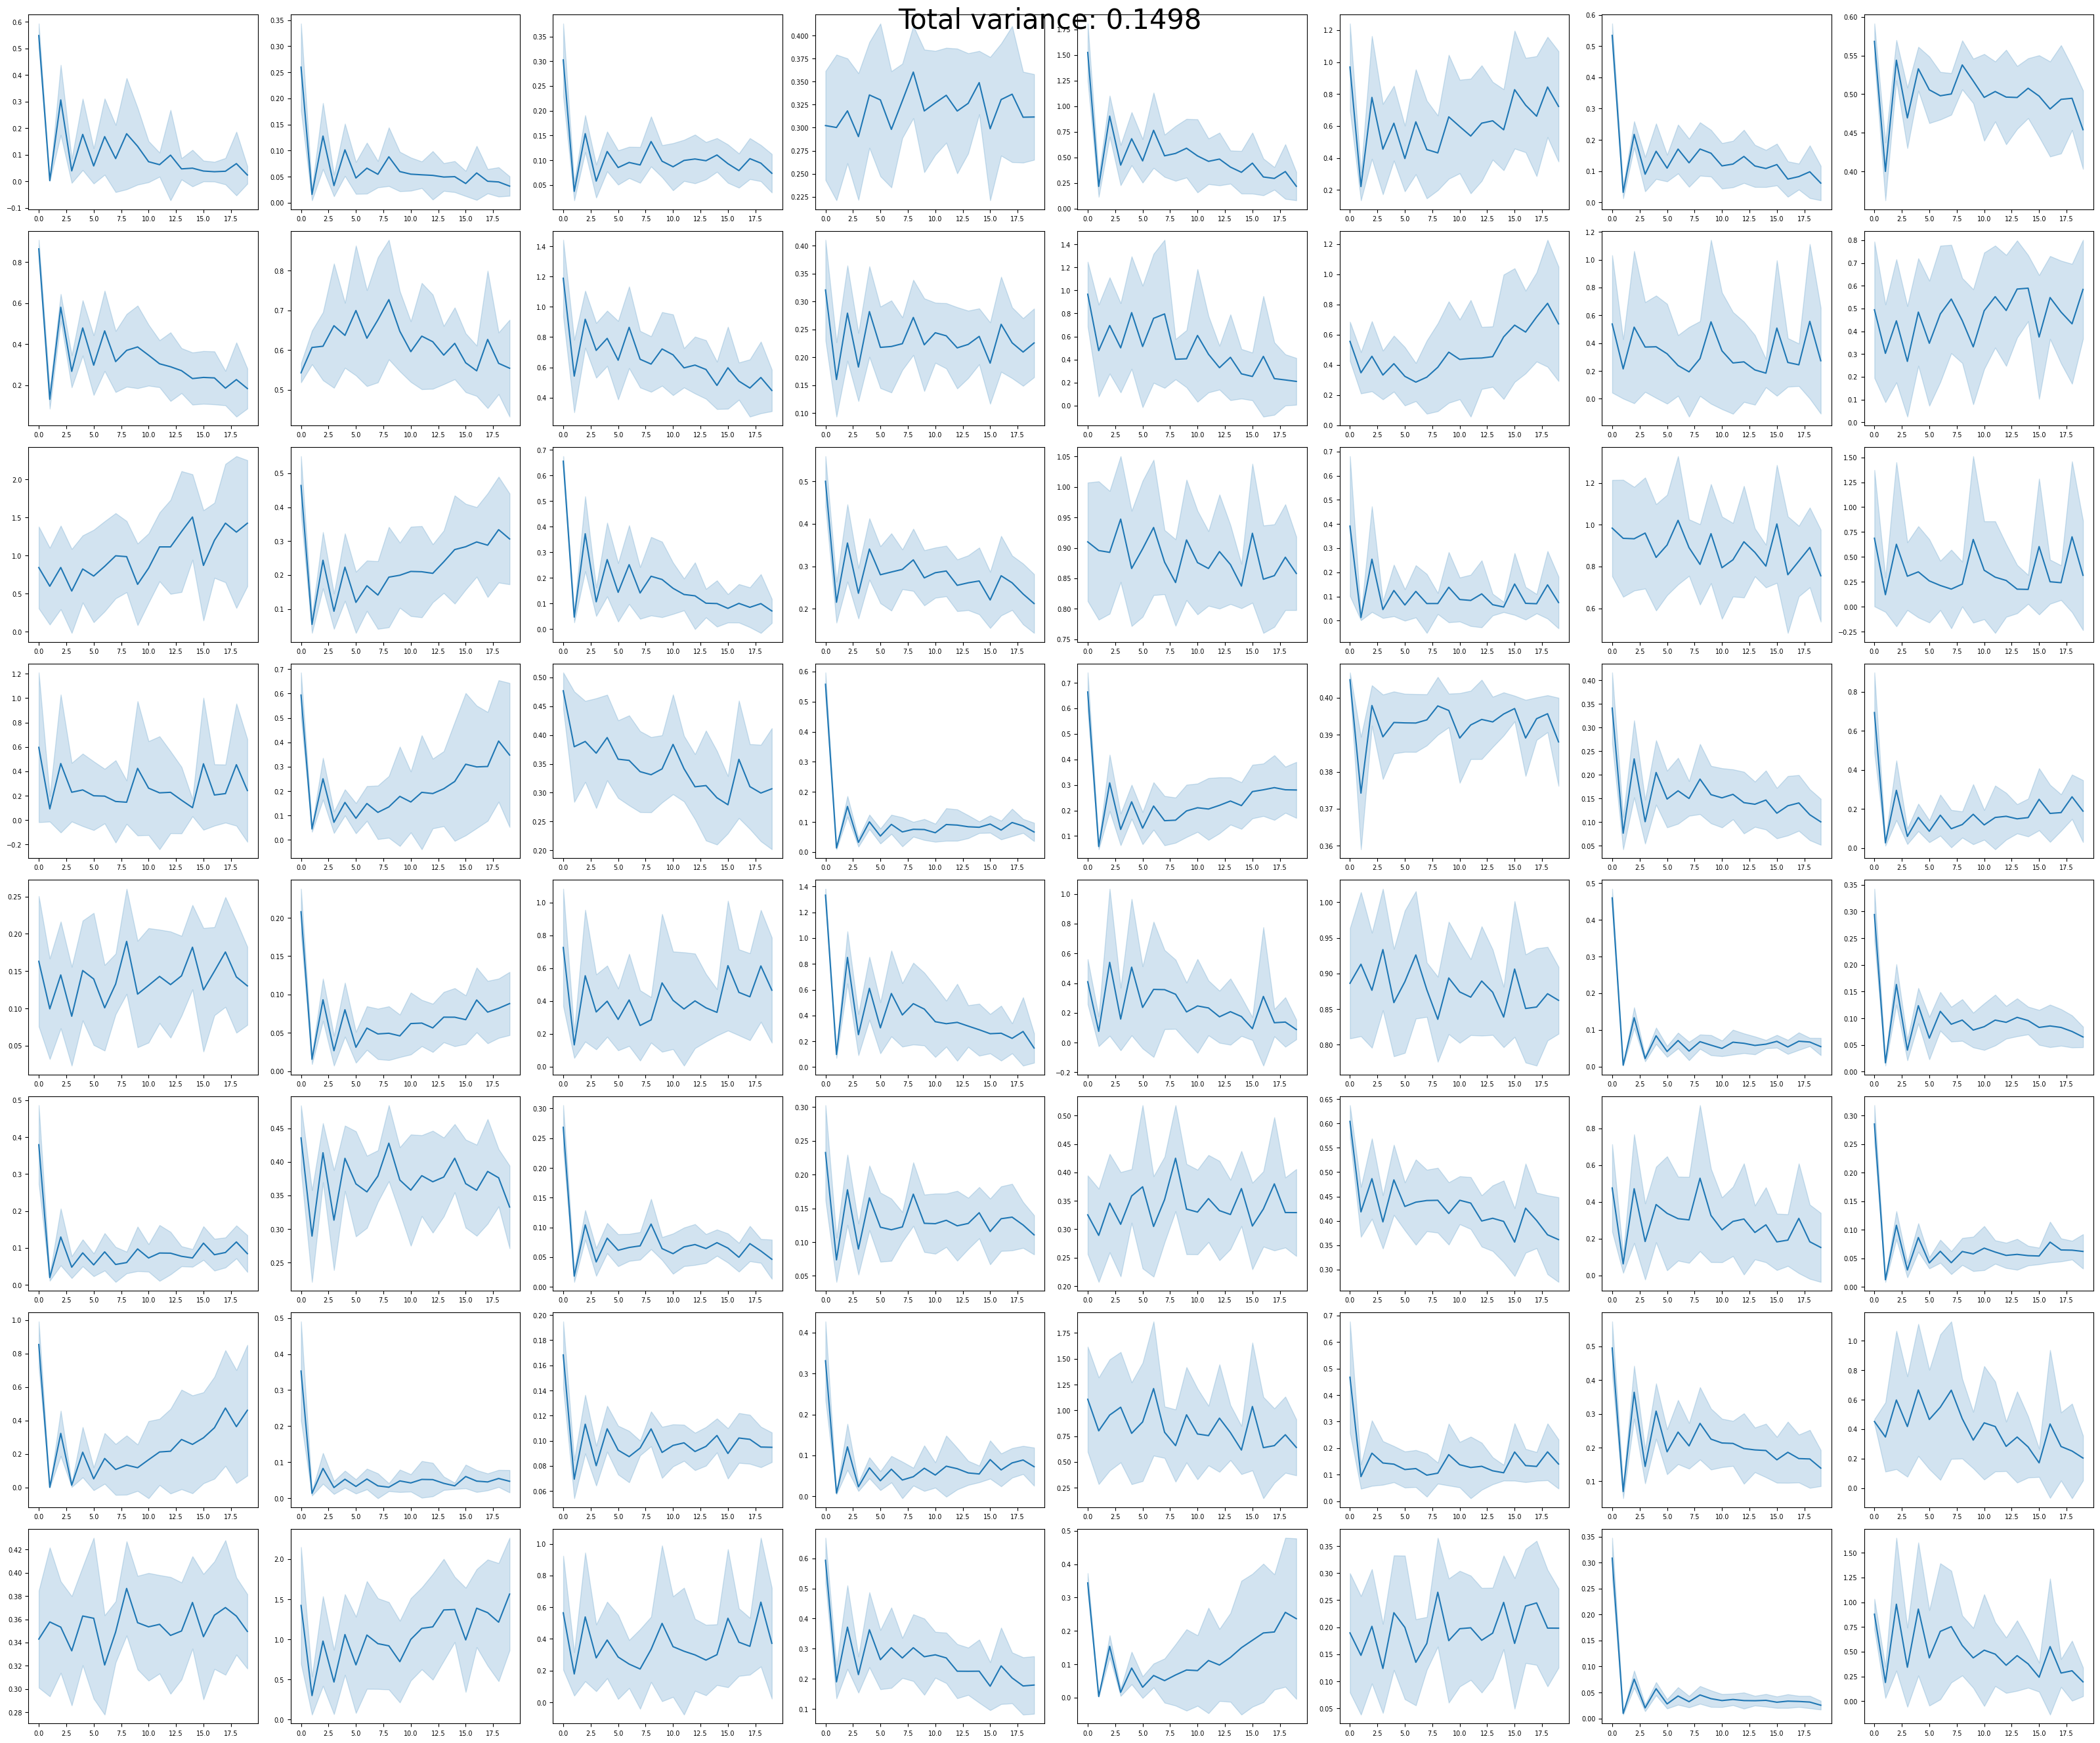

In [ ]:
plot_activity(hidden_size, net, idxs, 'C0')

h_all_std: [[3.58422607e-01 1.27059460e-01 2.02484000e-02 ... 1.20934896e-01
  2.28835806e-01 4.12075639e-01]
 [3.57983410e-01 5.47692776e-01 4.57207300e-03 ... 5.45263231e-01
  8.13815445e-02 4.17966187e-01]
 [1.38322594e-05 5.37216604e-01 2.32581934e-03 ... 6.51596929e-05
  4.62623168e-04 3.35699320e-01]
 ...
 [8.05383801e-01 2.11438909e-02 3.92214872e-07 ... 8.03634703e-01
  5.88838816e-01 2.67297596e-01]
 [5.92899382e-01 2.02060933e-03 7.36707125e-06 ... 6.98539793e-01
  8.41587424e-01 1.80781722e-01]
 [3.82957631e-03 5.74615657e-01 2.35905545e-03 ... 6.53277803e-03
  1.89828053e-01 6.68682232e-02]]


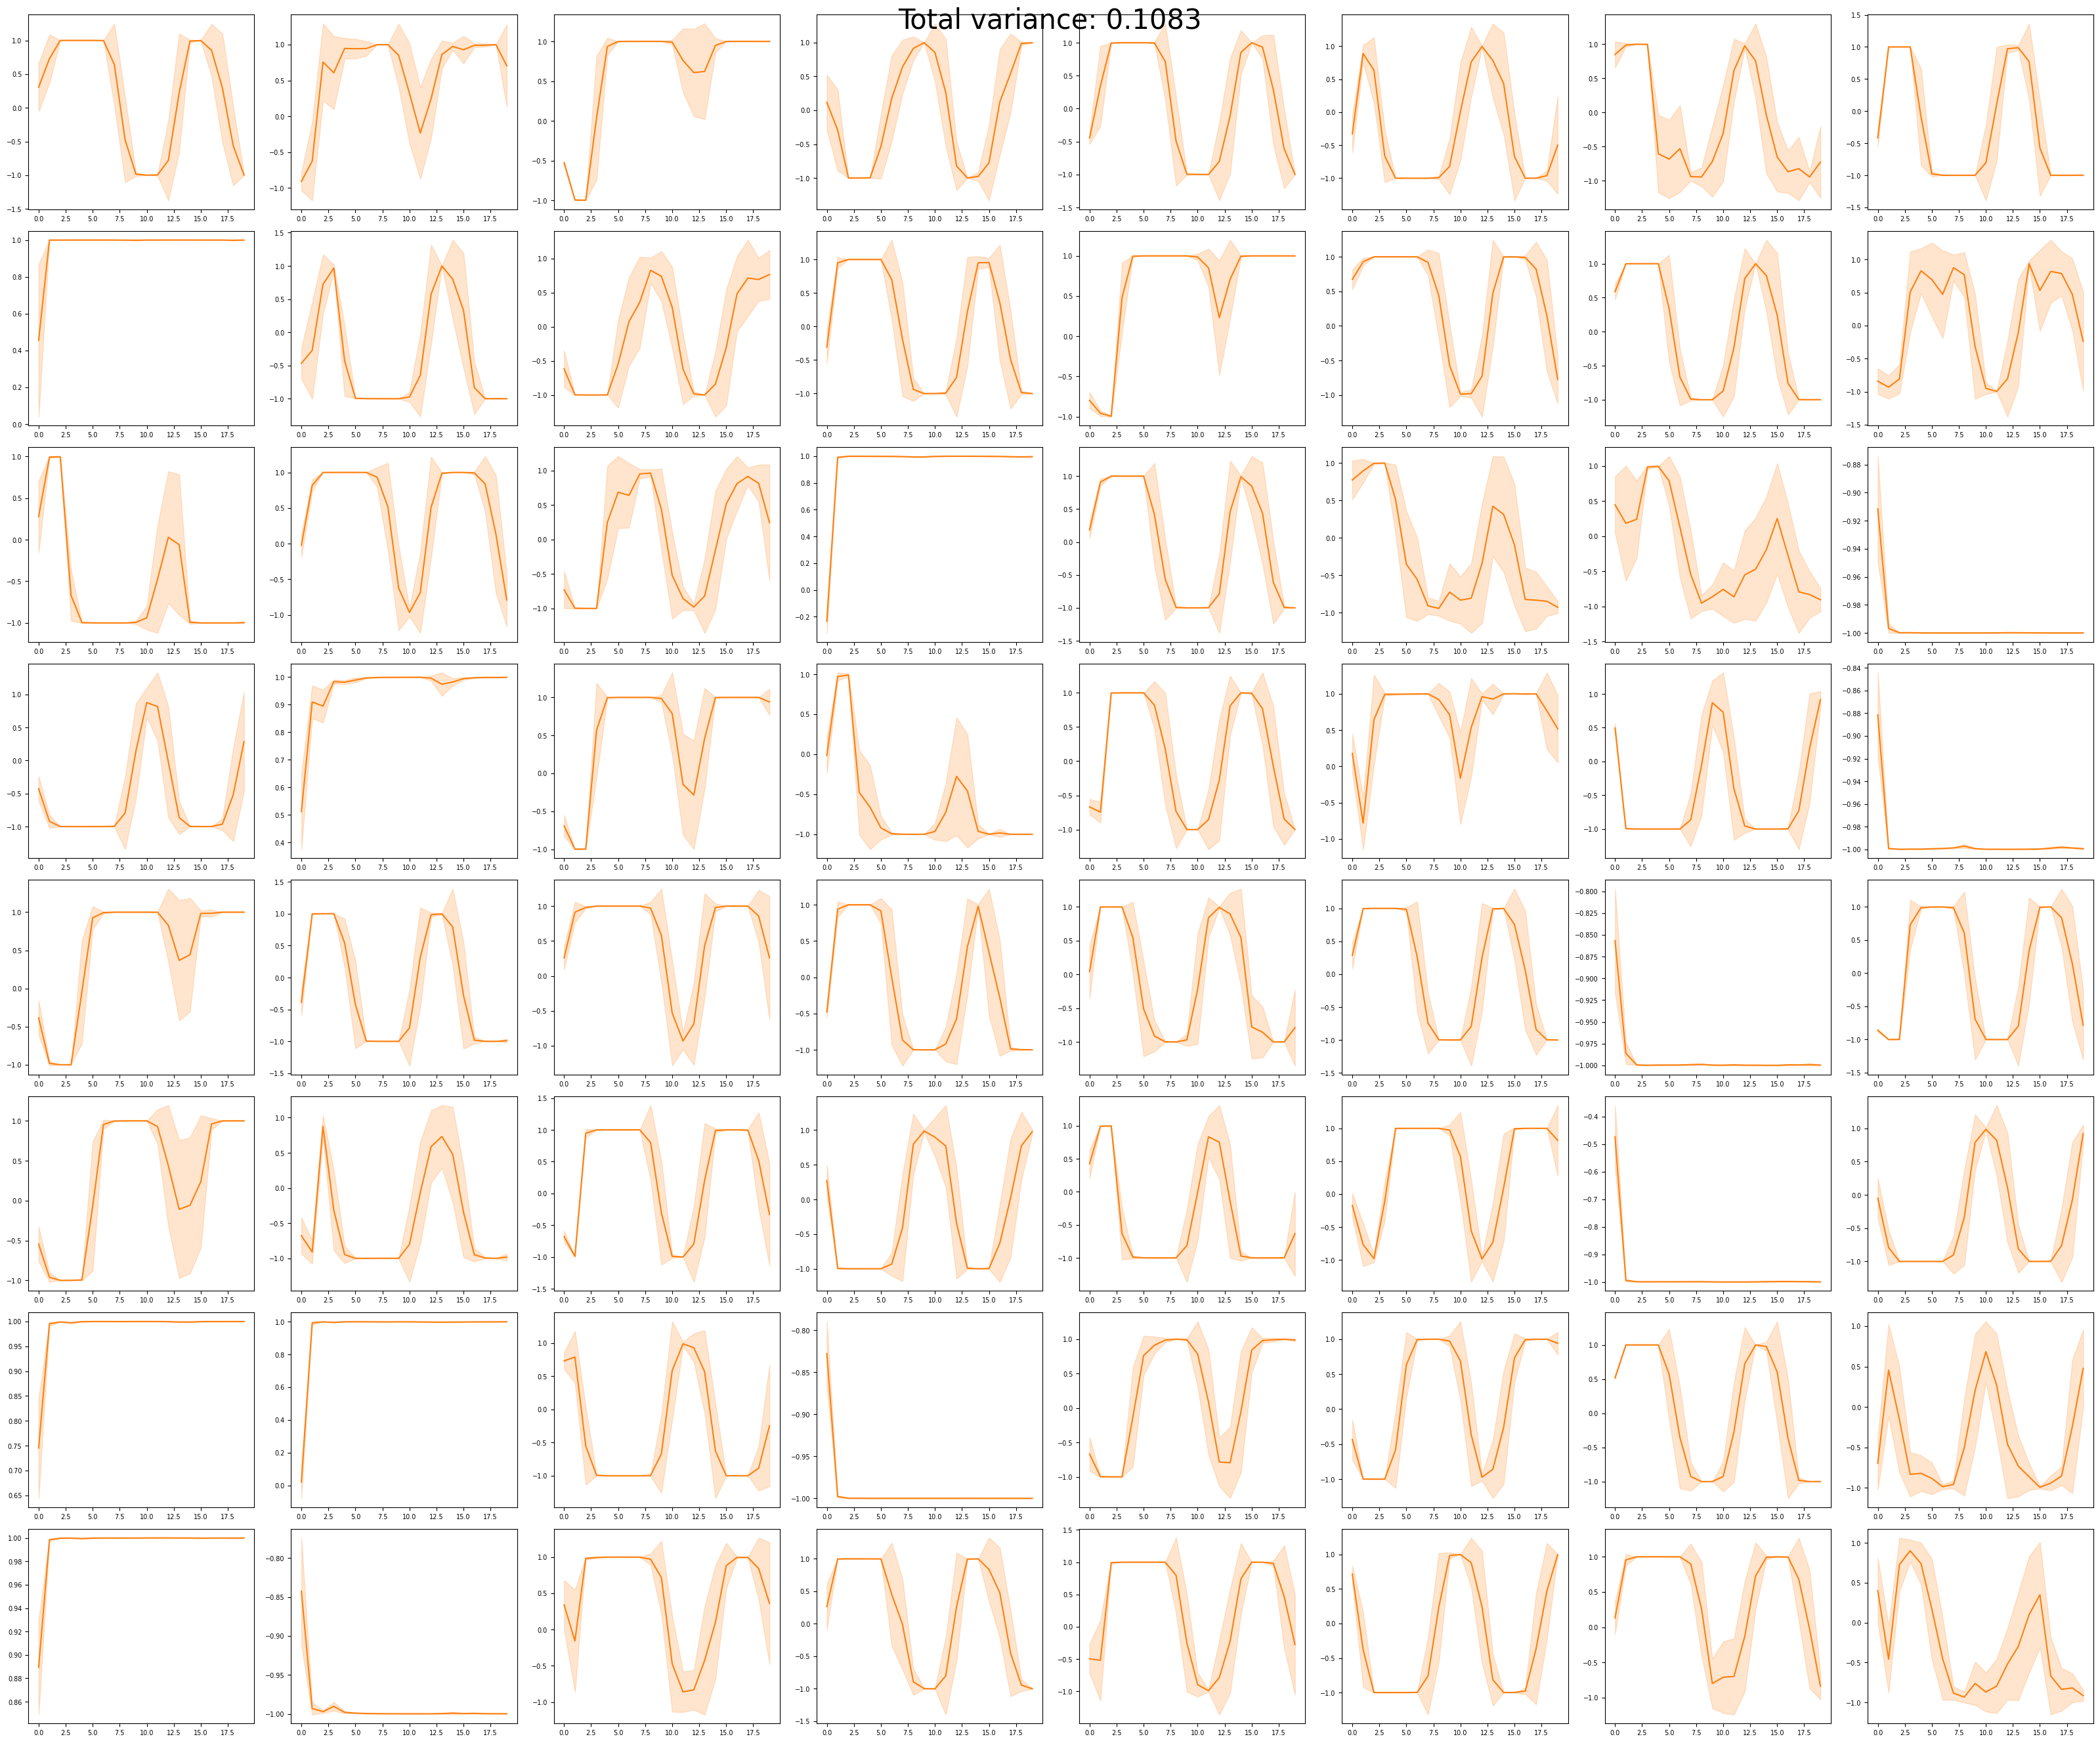

In [ ]:
plot_activity(hidden_size, simple_net, idxs, 'C1')